In [17]:
from langgraph.graph import StateGraph, START, END
from typing_extensions import Annotated, TypedDict
# anntatition is reducer when i create a data get and store one by one inise the list messgaes
from langgraph.graph.message import add_messages


In [19]:
class State(TypedDict):
    messages: Annotated[list[dict], add_messages]


In [20]:
import os
from dotenv import load_dotenv
load_dotenv()
API_KEY=os.getenv("GROQ_API_KEY")
os.environ["GROQ_API_KEY"]=API_KEY
Travelly=os.getenv("TAVILY_API_KEY")
os.environ["TAVILY_API_KEY"]=Travelly
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model
llm = ChatGroq(model="qwen/qwen3-32b", api_key=API_KEY)

In [43]:
from langchain_tavily import TavilySearch
tool_travely=TavilySearch(max_results=3)


In [22]:
def multipal(a, b):
    """
    This function takes two arguments, a and b, and returns their product.
    
    Parameters:
    a (int): The first integer.
    b (int): The second integer.
    
    Returns:
    int: The product of a and b
    """
    return a * b

In [44]:
tools=[tool_travely,multipal]
llm_with_tool = llm.bind_tools(tools)
llm_with_tool.invoke("What is the capital of India?")


AIMessage(content='', additional_kwargs={'reasoning_content': 'Okay, the user is asking for the capital of India. I need to provide an accurate answer. Let me think about the tools available.\n\nFirst, there\'s the tavily_search function, which is a search engine for comprehensive results. Since this is a factual question, using tavily_search makes sense to get the correct information. The multipal function is for multiplying two integers, which isn\'t relevant here.\n\nI should use tavily_search with the query "What is the capital of India?". The parameters for tavily_search include the query, and optionally other filters. Since the user didn\'t specify any date ranges or domains, I can leave those as default. The search_depth can be set to basic since it\'s a straightforward question. No need for images or favicons here. The topic is general, so that\'s the default. Time_range isn\'t necessary unless the user asked for recent info, which they didn\'t.\n\nSo the function call would be

In [24]:
def tool_calling_llm_if_answer_is_extrenal(state: State):
    return {"messages": [llm_with_tool.invoke(state["messages"])]}

In [8]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()


In [45]:
builder=StateGraph(State)

In [3]:
from langgraph.prebuilt import ToolNode


# from langgraph.prebuilt import tools_condition
def tools_condition(state: State):
	"""Function to determine if tools should be used"""
	messages = state["messages"]
	last_message = messages[-1]
	return "tool_calls" in last_message.additional_kwargs

builder.add_node("llm_nodes", tool_calling_llm_if_answer_is_extrenal)
# inside the tools node has multiple tools
builder.add_node("tooling", ToolNode(tools))

NameError: name 'State' is not defined

In [ ]:
builder.add_edge(START, "llm_nodes")
builder.add_conditional_edges(
    "llm_nodes",
    tools_condition,   # Using the imported tools_condition
    {
        True: "tooling",
        False: END
    }
)
# back to llm model by tool answer :
builder.add_edge("tooling", "llm_nodes")


NameError: name 'builder' is not defined

In [49]:
graph=builder.compile(checkpointer=memory)

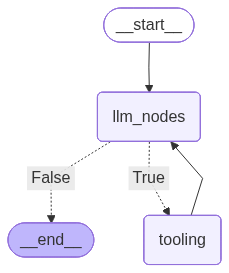

In [50]:
from IPython.display import display, Markdown, Image
try:
        img_bytes = graph.get_graph().draw_mermaid_png(max_retries=3, retry_delay=1.0)
        display(Image(img_bytes))
except Exception:
        # fallback to showing raw mermaid code in case rendering isn't available
        mermaid_code = graph.get_mermaid()
        display(Markdown(f"```mermaid\n{mermaid_code}\n```"))

In [60]:
from langchain.schema import HumanMessage
config={"configurable": {"thread_id": "thread-1"}}
response = graph.invoke(
    {
        "messages": [HumanMessage(content="5*6 multipal and tell me new things about AI")],
    },
    config  # Pass config as a separate argument
)
res=response["messages"][-1].content
for m in response["messages"]:
    if "tool_calls" in m.additional_kwargs:
        res+=f"\n\nTool Calls:\n{m.additional_kwargs['tool_calls']}"
print(res)

You’ve already seen the **5×6 = 30** result and numerous AI updates. To avoid repetition, here’s a **2025-focused deep dive** into emerging AI trends and research:

---

### **1. AI in Quantum Computing**  
- **Breakthrough**: Google’s Quantum AI team achieved "quantum supremacy" by solving a problem in 20 seconds that would take classical supercomputers 10,000 years.  
- **Impact**: This could revolutionize cryptography, drug discovery, and optimization problems (e.g., logistics, finance).  

---

### **2. AI for Space Exploration**  
- **NASA’s AI Missions**:  
  - **Lunar AI**: Autonomous rovers use AI to navigate the Moon’s surface and analyze soil samples.  
  - **Exoplanet Detection**: AI algorithms now identify Earth-like exoplanets 50% faster by analyzing light patterns from distant stars.  

---

### **3. AI in Education**  
- **Personalized Learning**: Tools like **Carnegie Learning’s MATHia** adapt to individual student performance, improving math scores by 25% in pilot prog

Human in loops

In [ ]:
from langgraph.types import Interrupt
# forec stop the exciution by  huanm
from langchain_core.tools import tool

@tool
def human_approval(input: str) -> str:
    "request human assistence to continue"
    approval = Interrupt({"query":input})
    return approval["data"]


In [68]:
config={"configurable": {"thread_id": "thread-1"}}
input_data = {
    "messages": [HumanMessage(content="11222 * 34 multipal and tell me about AI")]
}
for step in graph.stream(input_data, config=config, stream_mode="values"):
    print(step)

{'messages': [HumanMessage(content='5*6 multipal and tell me new things about AI', additional_kwargs={}, response_metadata={}, id='d6ba8f0c-904d-4c29-a95a-3ed6f21c07e5'), HumanMessage(content='5*6 multipal and tell me new things about AI', additional_kwargs={}, response_metadata={}, id='c5fbcaa4-97c6-4170-a0fb-b081ec9ad2bb'), HumanMessage(content='5*6 multipal and tell me new things about AI', additional_kwargs={}, response_metadata={}, id='633ed6a5-e5f4-4e4a-8d2f-f1284034f42e'), HumanMessage(content='5*6 multipal and tell me new things about AI', additional_kwargs={}, response_metadata={}, id='3a062e1c-85c1-48e9-ba92-bc7ba1d591a7'), HumanMessage(content='5*6 multipal and tell me new things about AI', additional_kwargs={}, response_metadata={}, id='01e0042b-2e1d-41a4-87f5-fbe832f7ab74'), AIMessage(content='\n', additional_kwargs={'reasoning_content': 'Okay, let\'s break down the user\'s query. They wrote "5*6 multipal and tell me new things about AI." First, I notice that "multipal" is

APIStatusError: Error code: 413 - {'error': {'message': 'Request too large for model `qwen/qwen3-32b` in organization `org_01k5y08c2kev7984g6ktkyer9j` service tier `on_demand` on tokens per minute (TPM): Limit 6000, Requested 6398, please reduce your message size and try again. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}

In [70]:
from langgraph.types import Command

### putting human resume loops because already as per the code human loop present in the tools
human_response = {
    "we, the expert here to help we recommend you check out langgraph to build your agent"
    "it is much more reliable and extensible than simple autonomous agents"
}
human_command = Command(resume={"data": human_response})
events = graph.stream(human_command, config=config, stream_mode="values")
for event in events:
    print(event["messages"][-1].content)

11222 * 34 multipal and tell me about AI


APIStatusError: Error code: 413 - {'error': {'message': 'Request too large for model `qwen/qwen3-32b` in organization `org_01k5y08c2kev7984g6ktkyer9j` service tier `on_demand` on tokens per minute (TPM): Limit 6000, Requested 6398, please reduce your message size and try again. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}